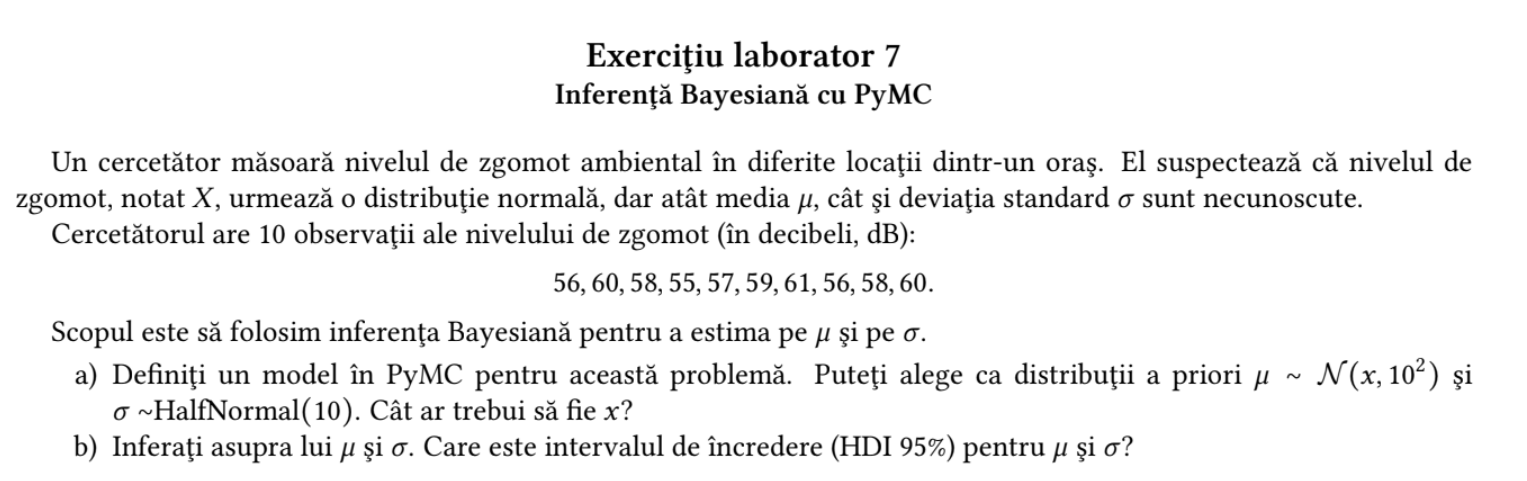

In [6]:
import os
os.environ["PYTENSOR_FLAGS"] = "cxx="

import pymc as pm
import numpy as np
import arviz as az

date_zgomot = np.array([56, 60, 58, 55, 57, 59, 61, 56, 58, 60])

with pm.Model() as model_zgomot:
    mu = pm.Normal("mu", mu=58, sigma=10)
    sigma = pm.HalfNormal("sigma", sigma=10)
    
    obs = pm.Normal("obs", mu=mu, sigma=sigma, observed=date_zgomot)

    idata = pm.sample(draws=2000, tune=2000, chains=4, random_seed=0)

summary = az.summary(idata, var_names=["mu", "sigma"], ci_prob=0.95)
print(summary)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [mu, sigma]


Output()

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 25 seconds.


       mean    sd eti95_lb eti95_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
mu       58  0.77       56       60     4190     4424  1.00     0.012   0.014
sigma  2.33  0.67      1.4        4     4985     4513  1.00      0.01   0.013
